# Analyze SMETANA and SteadyCom results

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns

In [2]:
import matplotlib as mpl

colors_hex = ["#b69cfd", "#832522", "#86d7a9", "#d725a3", "#11e38c", "#f82f65", "#2e9568", "#d67381", "#20d8fd", "#6c096a", "#b9b9b9", "#0a433b", "#68affc"]
from matplotlib.colors import ListedColormap


cmap = ListedColormap(colors_hex)

# SMETANA

In [3]:
ecoli_detailed = pd.read_csv("../output/Guillen2021/smetana/_detailed.tsv",sep="\t")
ecoli_global = pd.read_csv("../output/Guillen2021/smetana/_global.tsv",sep="\t")

gut_detailed_no_coupling = pd.read_csv("../output/Venturelli2018/smetana/no_coupling_detailed.tsv",sep="\t")
gut_detailed = pd.read_csv("../output/Venturelli2018/smetana/_detailed.tsv",sep="\t")
gut_global = pd.read_csv("../output/Venturelli2018/smetana/_global.tsv",sep="\t")

#### Check that SMETANA identifies auxotrophies

In [4]:
auxotrophies_ecoli_df = pd.read_csv("../output/Guillen2021/auxotrophies.tsv",sep="\t",index_col=[0,1])
auxotrophies_ecoli_df = auxotrophies_ecoli_df['0']


# Find members that are included in the SMETANA community prediction
members_viable_smetana_ecoli = list(set(list(ecoli_detailed.receiver.unique())+list(ecoli_detailed.donor.unique())))

# Dictionary to store if each (member, metabolite) pair is matched (True/False)
match_essentiality = {}

# Go through each viable member from SMETANA
for member in members_viable_smetana_ecoli:
    
    # Remove 'mutant_' prefix to match auxotrophy data
    member_aux = member.split("mutant_")[1]
    
    # Skip if this mutant isn’t in the auxotrophy data
    if member_aux not in auxotrophies_ecoli_df.index.get_level_values(0):
        continue
        
    # Get auxotrophic reactions for this mutant
    aux_ser = auxotrophies_ecoli_df.xs(member_aux)
    aux_rxns = aux_ser.index.values

    # Check each auxotrophic reaction
    for rxn in aux_rxns:
        
        # Get metabolite name from reaction (e.g., R_EX_btn_e → M_btn_e)
        met = "M_" + rxn.split("R_EX_")[1]
        
        # Look for rows where the mutant received this metabolite
        sub_df = ecoli_detailed[
            (ecoli_detailed.receiver == member) &
            (ecoli_detailed.compound == met)
        ]
        
        # Save whether a match was found
        match_essentiality[(member, met)] = not sub_df.empty

In [5]:
pd.Series(match_essentiality)

Series([], dtype: object)

**Dependency on metabolite**

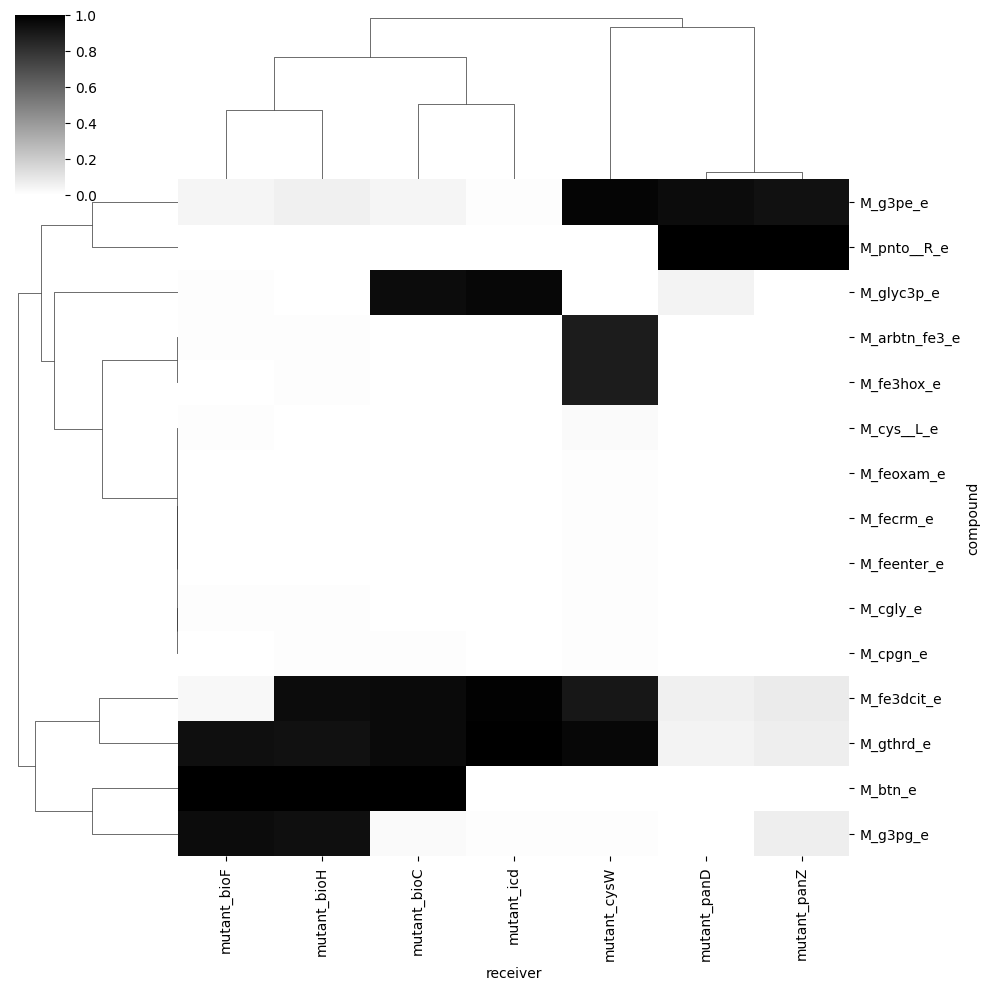

In [6]:
ecoli_detailed_plot = ecoli_detailed[["receiver","compound","mus"]].groupby(["receiver","compound"]).mean()["mus"].unstack().fillna(0)

g = sns.clustermap(ecoli_detailed_plot.T,cmap="binary",vmax=1.0)

**Dependency on member**

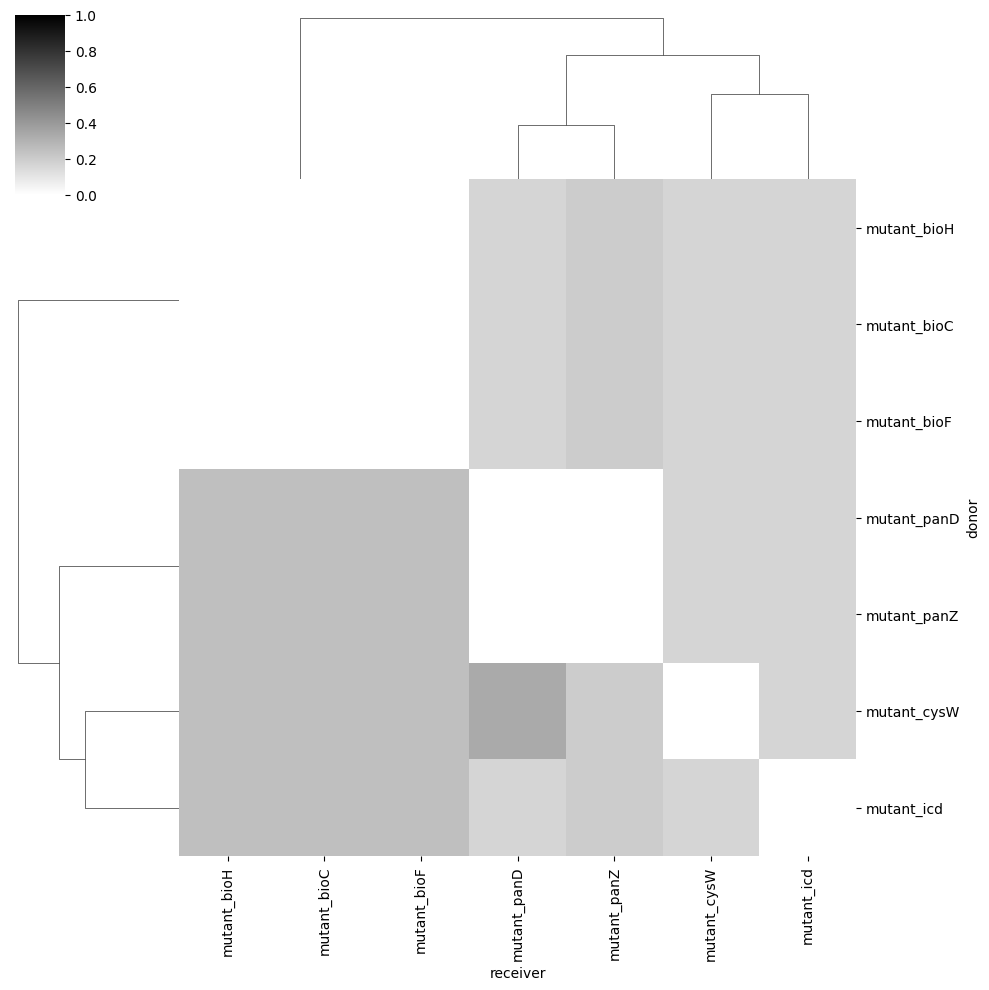

In [7]:
ecoli_detailed_member = ecoli_detailed[["community","receiver","donor","scs"]].drop_duplicates().sort_values(by=["receiver","donor"],ascending=False)

ecoli_detailed_member_plot = ecoli_detailed_member[["receiver","donor","scs"]].groupby(["receiver","donor"]).mean()["scs"].unstack().fillna(0)

sns.clustermap(ecoli_detailed_member_plot.T,
               cmap="binary",vmax=1.0)

### Gut microbiome

**Dependency on metabolite**

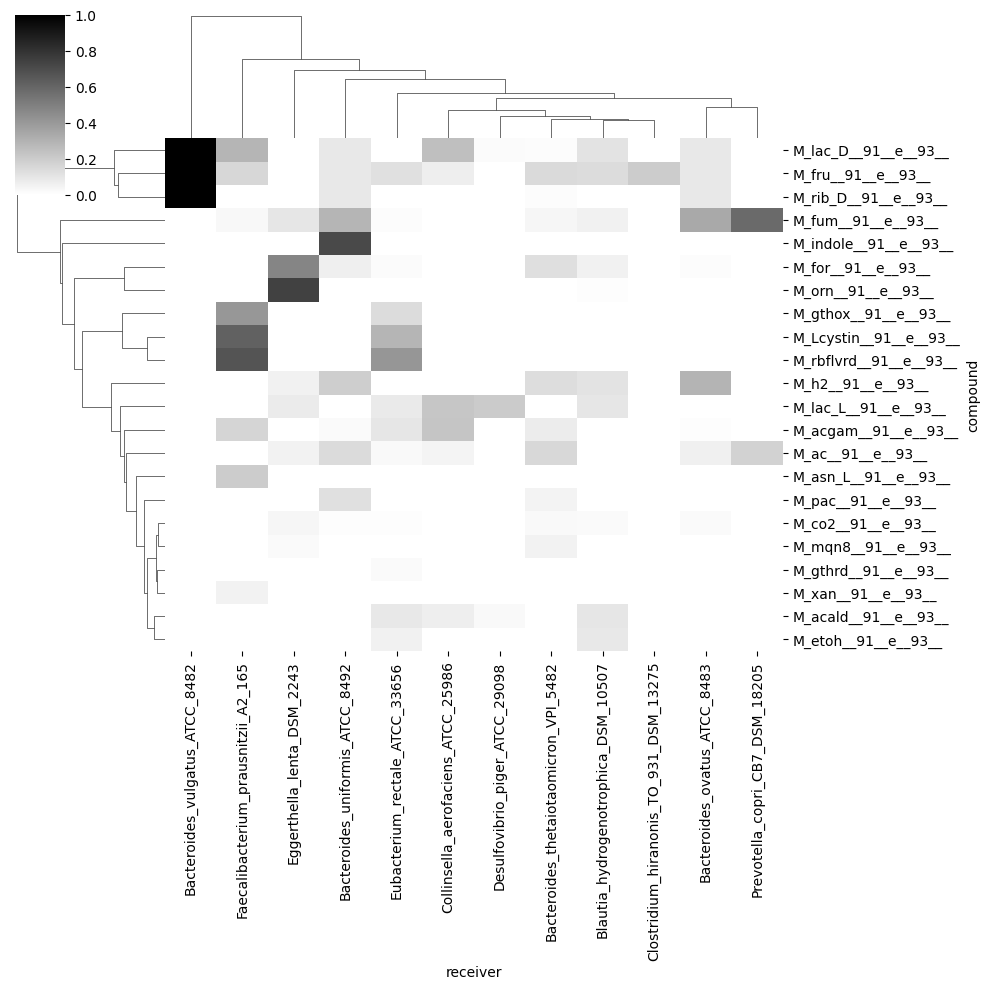

In [8]:
gut_detailed_met_plot = gut_detailed_no_coupling[["receiver","compound","mus"]].groupby(["receiver","compound"]).mean()["mus"].unstack().fillna(0)

sns.clustermap(gut_detailed_met_plot.T,cmap="binary",vmax=1.0)

# SteadyCom

**Load m9 media compounds**

*For E. coli mutants (M9 medium to force growth of specific members)*

In [9]:
media_db = pd.read_csv("https://raw.githubusercontent.com/cdanielmachado/carveme/refs/heads/master/carveme/data/input/media_db.tsv",sep="\t")
compounds = list(media_db[media_db.medium=="M9"].compound.values)
m9_ecoli = ["M_"+met+"_e" for met in compounds]
m9_gut = ["M_"+met+"__91__e__93__" for met in compounds]

**Load data**

*E.coli mutants*

In [10]:
growth_ecoli = pd.read_csv("../output/Guillen2021/steadycom/no_abundance/growth.tsv",sep="\t",index_col=0)
relative_abundance_ecoli = pd.read_csv("../output/Guillen2021/steadycom/no_abundance/relative_abundance.tsv",sep="\t",index_col=0)
cross_feeding_ecoli = pd.read_csv("../output/Guillen2021/steadycom/no_abundance/cross_feeding.tsv",sep="\t")

cross_feeding_ecoli = cross_feeding_ecoli[~cross_feeding_ecoli.compound.isin(m9_ecoli)]



growth_fixed_abundance_ecoli = pd.read_csv("../output/Guillen2021/steadycom/fixed_abundance/growth.tsv",sep="\t",index_col=0)
relative_abundance_fixed_abundance_ecoli = pd.read_csv("../output/Guillen2021/steadycom/fixed_abundance/relative_abundance.tsv",sep="\t",index_col=0)
cross_feeding_fixed_abundance_ecoli = pd.read_csv("../output/Guillen2021/steadycom/fixed_abundance/cross_feeding.tsv",sep="\t")

cross_feeding_fixed_abundance_ecoli = cross_feeding_fixed_abundance_ecoli[~cross_feeding_fixed_abundance_ecoli.compound.isin(m9_ecoli)]

*Gut microbiome*

In [11]:
growth_gut = pd.read_csv("../output/Venturelli2018/steadycom/no_abundance/growth.tsv",sep="\t",index_col=0)
relative_abundance_gut = pd.read_csv("../output/Venturelli2018/steadycom/no_abundance/relative_abundance.tsv",sep="\t",index_col=0)
cross_feeding_gut = pd.read_csv("../output/Venturelli2018/steadycom/no_abundance/cross_feeding.tsv",sep="\t")

cross_feeding_gut = cross_feeding_gut[~cross_feeding_gut.compound.isin(m9_gut)]


growth_fixed_abundance_gut = pd.read_csv("../output/Venturelli2018/steadycom/fixed_abundance/growth.tsv",sep="\t",index_col=0)
relative_abundance_fixed_abundance_gut = pd.read_csv("../output/Venturelli2018/steadycom/fixed_abundance/relative_abundance.tsv",sep="\t",index_col=0)
cross_feeding_fixed_abundance_gut = pd.read_csv("../output/Venturelli2018/steadycom/fixed_abundance/cross_feeding.tsv",sep="\t")

cross_feeding_fixed_abundance_gut = cross_feeding_fixed_abundance_gut[~cross_feeding_fixed_abundance_gut.compound.isin(m9_gut)]

#### Check that SteadyCom identifies auxotrophies

In [12]:
auxotrophies_ecoli_df = pd.read_csv("../output/Guillen2021/auxotrophies.tsv",sep="\t",index_col=[0,1])
auxotrophies_ecoli_df = auxotrophies_ecoli_df['0']


# Find members that are included in the SteadyCom community prediction
members_viable_smetana_ecoli = list(set(list(cross_feeding_ecoli.receiver.dropna().unique())+list(cross_feeding_ecoli.donor.dropna().unique())))

# Dictionary to store if each (member, metabolite) pair is matched (True/False)
match_essentiality = {}

# Go through each viable member from SMETANA
for member in members_viable_smetana_ecoli:
    
    # Remove 'mutant_' prefix to match auxotrophy data
    member_aux = member
    
    # Skip if this mutant isn’t in the auxotrophy data
    if member_aux not in auxotrophies_ecoli_df.index.get_level_values(0):
        continue
        
    # Get auxotrophic reactions for this mutant
    aux_ser = auxotrophies_ecoli_df.xs(member_aux)
    aux_rxns = aux_ser.index.values

    # Check each auxotrophic reaction
    for rxn in aux_rxns:
        
        # Get metabolite name from reaction (e.g., R_EX_btn_e → M_btn_e)
        met = "M_" + rxn.split("R_EX_")[1]
        
        # Look for rows where the mutant received this metabolite
        sub_df = cross_feeding_ecoli[
            (cross_feeding_ecoli.receiver == member) &
            (cross_feeding_ecoli.compound == met)
        ]
        
        # Save whether a match was found
        match_essentiality[(member, met)] = not sub_df.empty

In [13]:
pd.Series(match_essentiality)

mutant_bioC  M_btn_e    False
mutant_bioH  M_btn_e    False
dtype: bool

In [14]:
# Find members that are included in the SteadyCom community prediction
members_viable_smetana_ecoli = list(set(list(cross_feeding_fixed_abundance_ecoli.receiver.dropna().unique())+list(cross_feeding_fixed_abundance_ecoli.donor.dropna().unique())))

# Dictionary to store if each (member, metabolite) pair is matched (True/False)
match_essentiality = {}

# Go through each viable member from SMETANA
for member in members_viable_smetana_ecoli:
    
    # Remove 'mutant_' prefix to match auxotrophy data
    member_aux = member
    
    # Skip if this mutant isn’t in the auxotrophy data
    if member_aux not in auxotrophies_ecoli_df.index.get_level_values(0):
        continue
        
    # Get auxotrophic reactions for this mutant
    aux_ser = auxotrophies_ecoli_df.xs(member_aux)
    aux_rxns = aux_ser.index.values

    # Check each auxotrophic reaction
    for rxn in aux_rxns:
        
        # Get metabolite name from reaction (e.g., R_EX_btn_e → M_btn_e)
        met = "M_" + rxn.split("R_EX_")[1]
        
        # Look for rows where the mutant received this metabolite
        sub_df = cross_feeding_fixed_abundance_ecoli[
            (cross_feeding_fixed_abundance_ecoli.receiver == member) &
            (cross_feeding_fixed_abundance_ecoli.compound == met)
        ]
        
        # Save whether a match was found
        match_essentiality[(member, met)] = not sub_df.empty

In [15]:
pd.Series(match_essentiality)

mutant_bioF  M_btn_e         True
mutant_cysW  M_cys__L_e      True
             M_o2_e         False
mutant_bioC  M_btn_e         True
mutant_bioH  M_btn_e         True
mutant_panZ  M_pnto__R_e     True
mutant_panD  M_pnto__R_e     True
dtype: bool

### E. coli mutants - fixed abundance

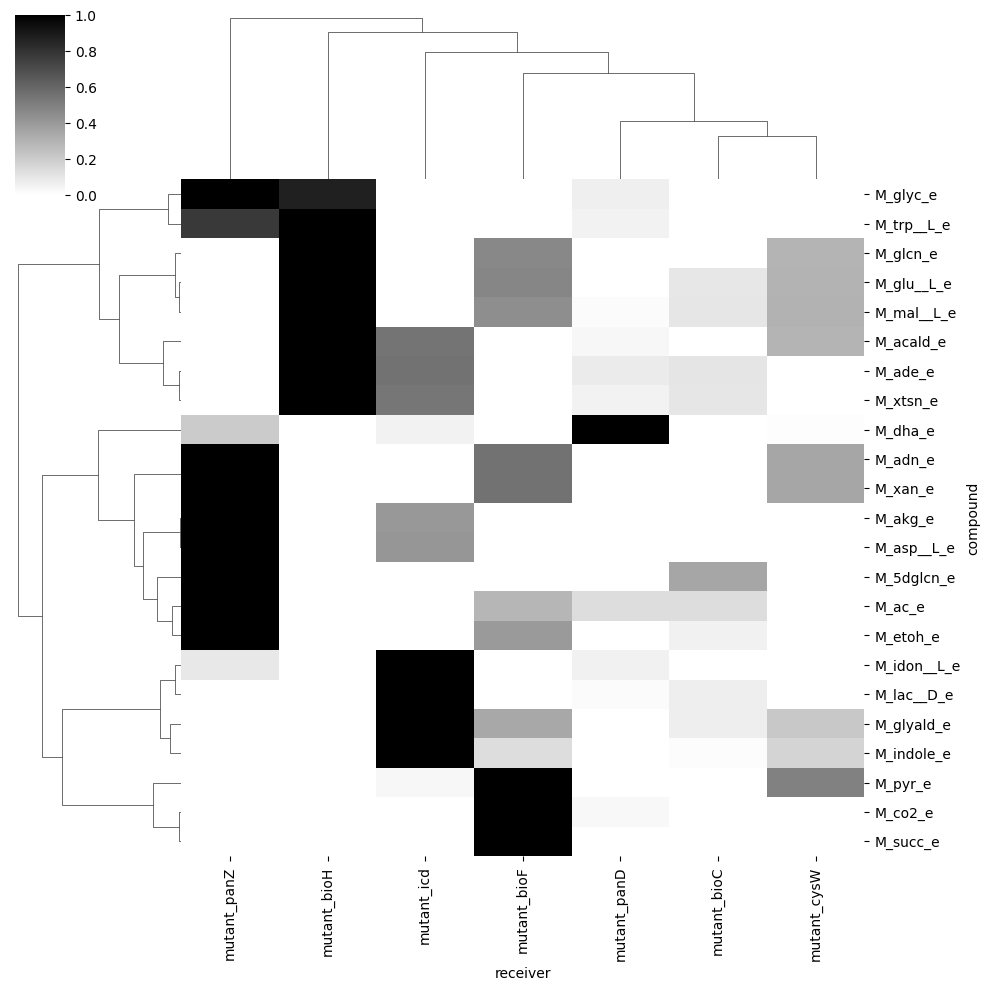

In [16]:
receivers_ecoli = cross_feeding_fixed_abundance_ecoli.copy()
receivers_ecoli = receivers_ecoli.dropna().groupby(["receiver","compound"]).sum()["rate?"]\
                    .unstack().fillna(0)
receivers_ecoli = receivers_ecoli.loc[:,receivers_ecoli.sum()>1]
sns.clustermap(receivers_ecoli.T,
               cmap="binary",
               xticklabels=1,
               yticklabels=1,
               method="ward",
              standard_scale=0)

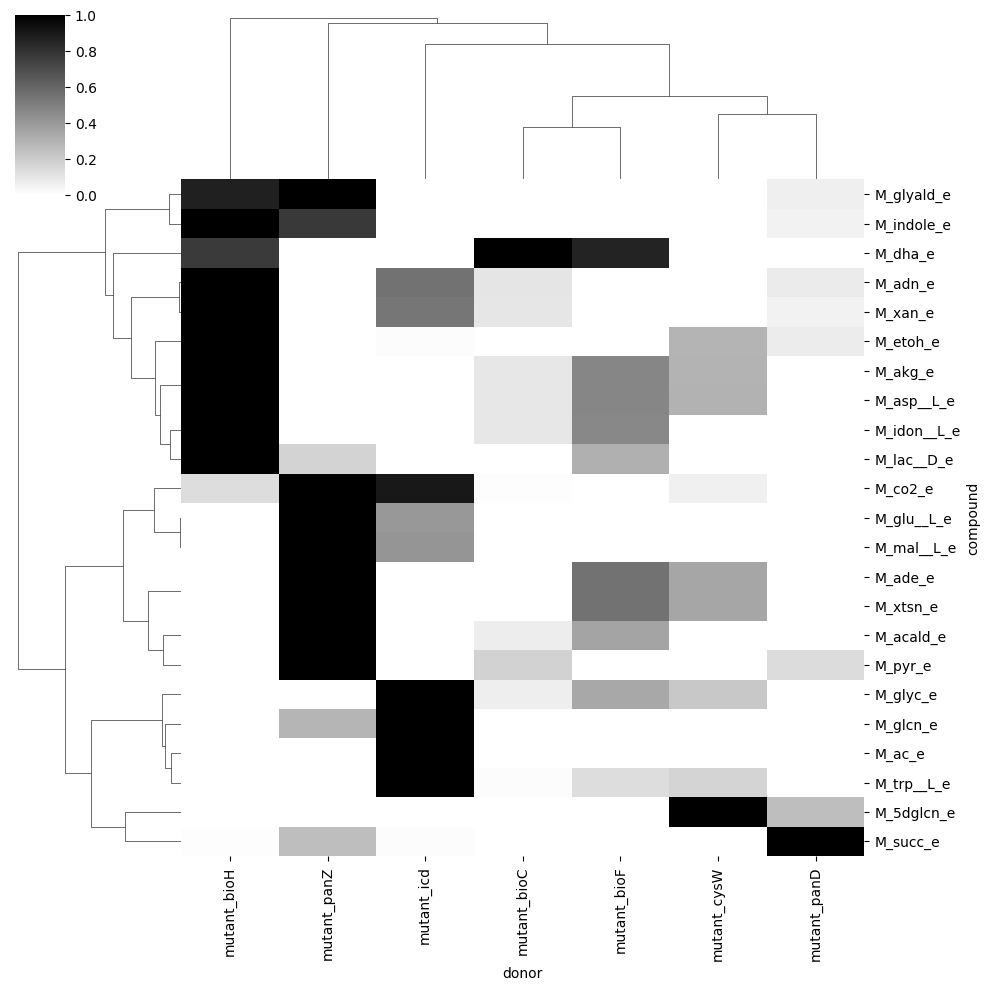

In [17]:
donors_ecoli = cross_feeding_fixed_abundance_ecoli.copy()
donors_ecoli = donors_ecoli.dropna().groupby(["donor","compound"]).sum()["rate?"]\
                    .unstack().fillna(0)
donors_ecoli = donors_ecoli.loc[:,donors_ecoli.sum()>1]
sns.clustermap(donors_ecoli.T,
               cmap="binary",
               xticklabels=1,
               yticklabels=1,
               method="ward",
              standard_scale=0)

<Axes: xlabel='receiver', ylabel='donor'>

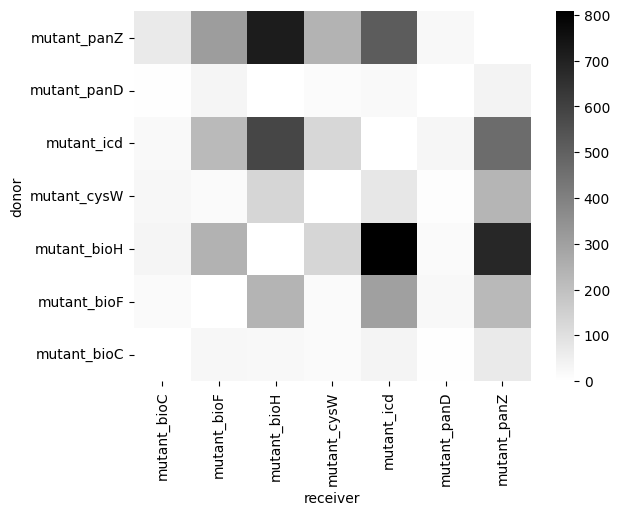

In [18]:
receivers_ecoli = cross_feeding_fixed_abundance_ecoli.copy()
receivers_ecoli = receivers_ecoli.dropna().groupby(["receiver","donor"]).sum()["rate?"]\
                    .unstack().fillna(0)
receivers_ecoli = receivers_ecoli.sort_index().T.sort_index(ascending=False).T
sns.heatmap(receivers_ecoli.T,
               cmap="binary",
               xticklabels=1,
               yticklabels=1,
               )

### E. coli mutants - not fixed abundance

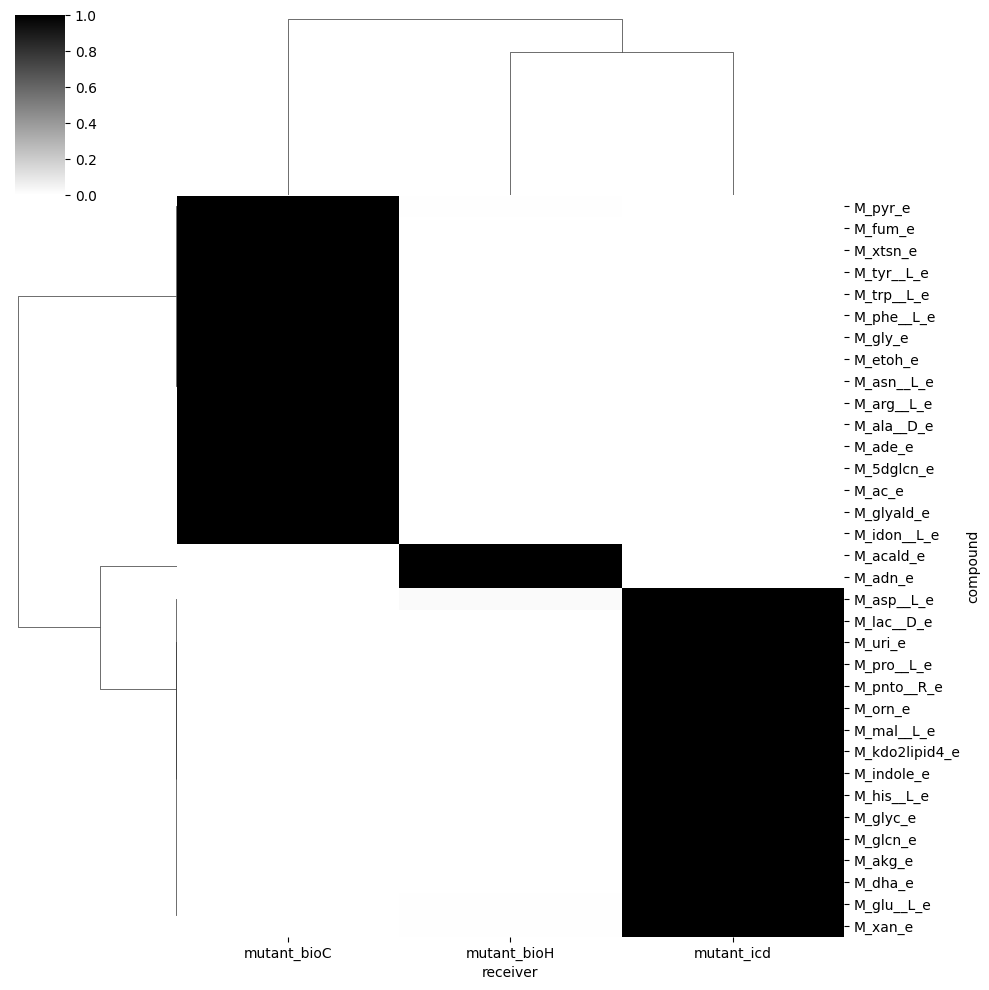

In [19]:
receivers_ecoli = cross_feeding_ecoli.copy()
receivers_ecoli = receivers_ecoli.dropna().groupby(["receiver","compound"]).sum()["rate?"]\
                    .unstack().fillna(0)
receivers_ecoli = receivers_ecoli#.loc[:,receivers_ecoli.sum()>1]
sns.clustermap(receivers_ecoli.T,
               cmap="binary",
               xticklabels=1,
               yticklabels=1,
               method="ward",
              standard_scale=0)

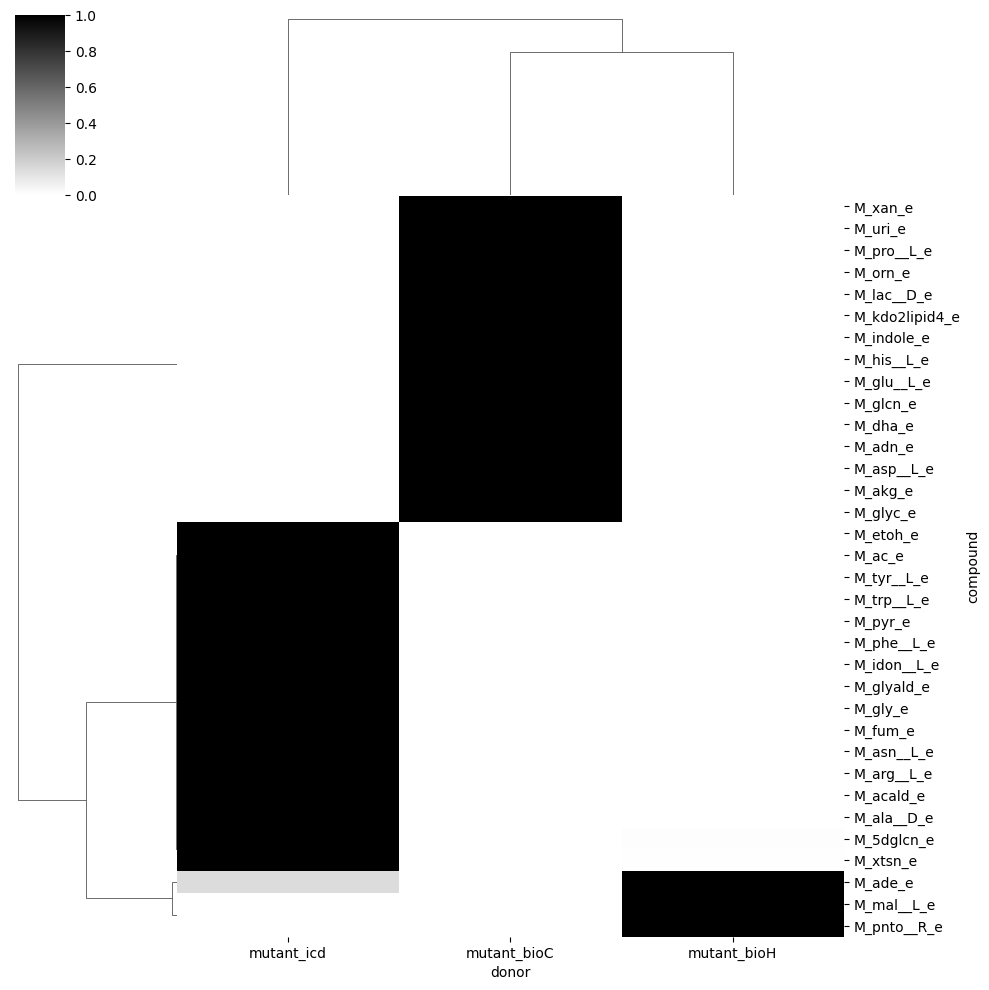

In [20]:
donors_ecoli = cross_feeding_ecoli.copy()
donors_ecoli = donors_ecoli.dropna().groupby(["donor","compound"]).sum()["rate?"]\
                    .unstack().fillna(0)
donors_ecoli = donors_ecoli#.loc[:,donors_ecoli.sum()>1]
sns.clustermap(donors_ecoli.T,
               cmap="binary",
               xticklabels=1,
               yticklabels=1,
               method="ward",
              standard_scale=0)

<Axes: xlabel='receiver', ylabel='donor'>

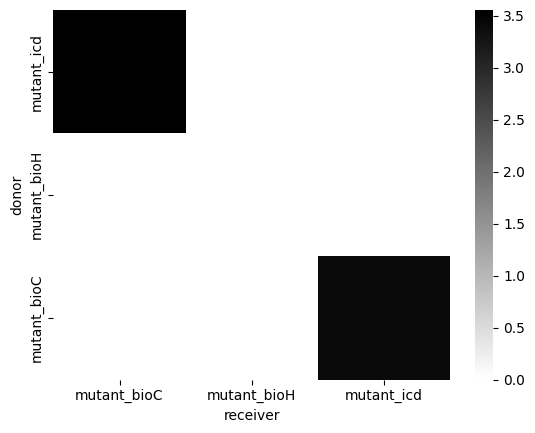

In [21]:
receivers_ecoli = cross_feeding_ecoli[cross_feeding_ecoli["rate?"]>1e-5]
receivers_ecoli = receivers_ecoli.dropna().groupby(["receiver","donor"]).sum()["rate?"]\
                    .unstack().fillna(0)
receivers_ecoli = receivers_ecoli.sort_index().T.sort_index(ascending=False).T
sns.heatmap(receivers_ecoli.T,
               cmap="binary",
               xticklabels=1,
               yticklabels=1,
               )

### Gut microbiome - fixed abundance

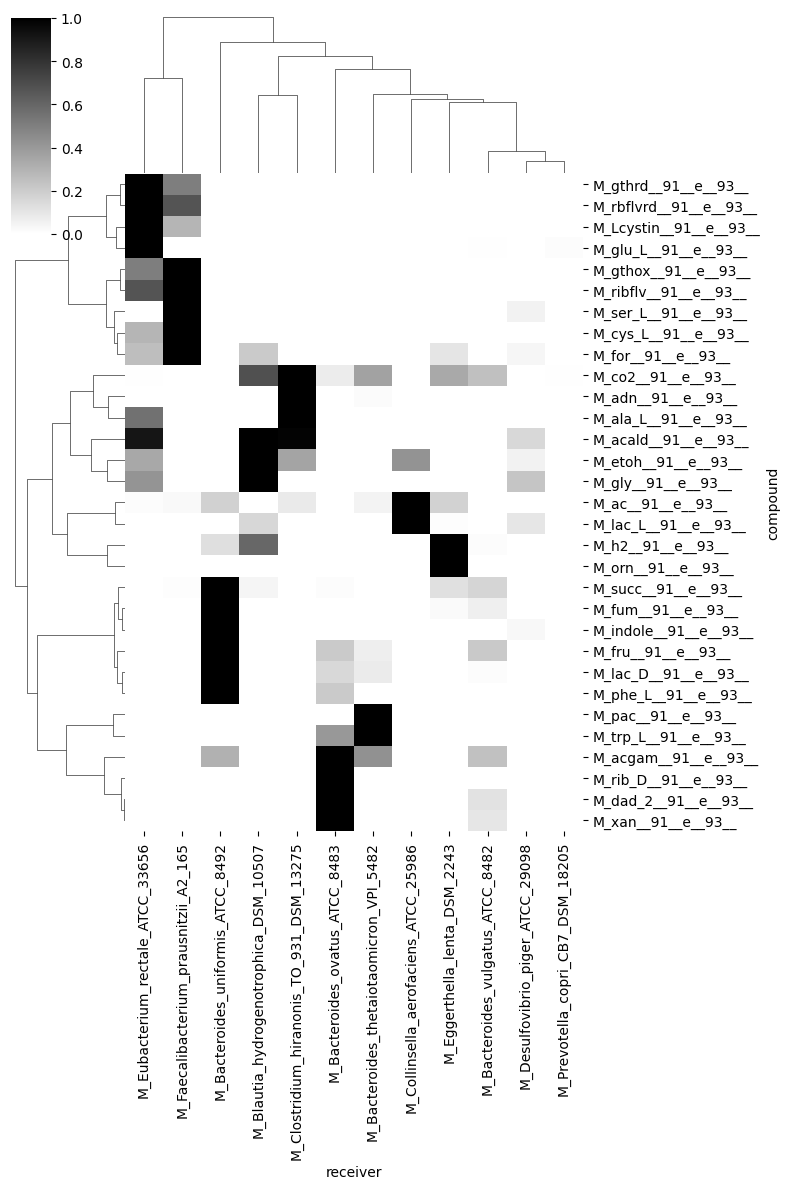

In [22]:
receivers_gut = cross_feeding_fixed_abundance_gut.copy()
receivers_gut = receivers_gut.dropna().groupby(["receiver","compound"]).sum()["rate?"]\
                    .unstack().fillna(0)


receivers_gut = receivers_gut.loc[:,receivers_gut.sum()>1]

sns.clustermap(receivers_gut.T,
               cmap="binary",
               xticklabels=1,
               yticklabels=1,
               method="ward",
               figsize=(8,12),
               standard_scale=0
              )

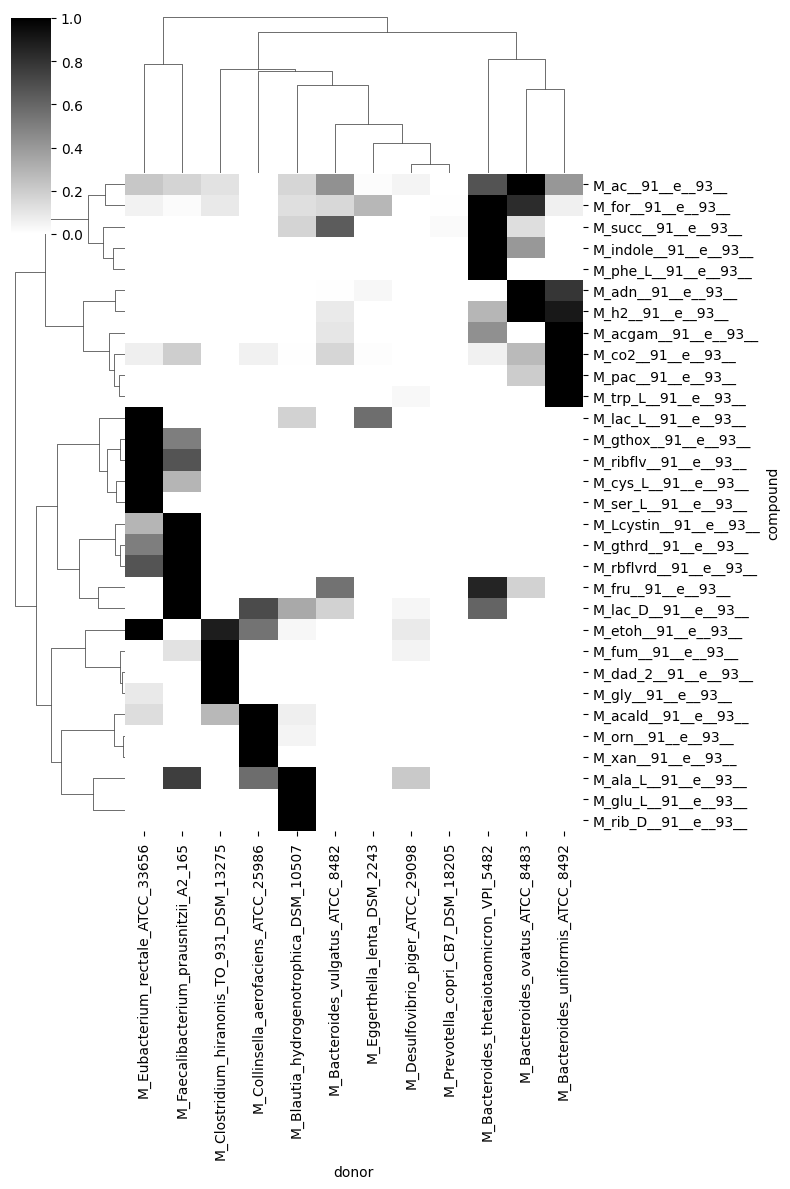

In [23]:
donors_gut = cross_feeding_fixed_abundance_gut.copy()
donors_gut = donors_gut.dropna().groupby(["donor","compound"]).sum()["rate?"]\
                    .unstack().fillna(0)


donors_gut = donors_gut.loc[:,donors_gut.sum()>1]

sns.clustermap(donors_gut.T,
               cmap="binary",
               xticklabels=1,
               yticklabels=1,
               method="ward",
               figsize=(8,12),
               standard_scale=0)

<Axes: xlabel='receiver', ylabel='donor'>

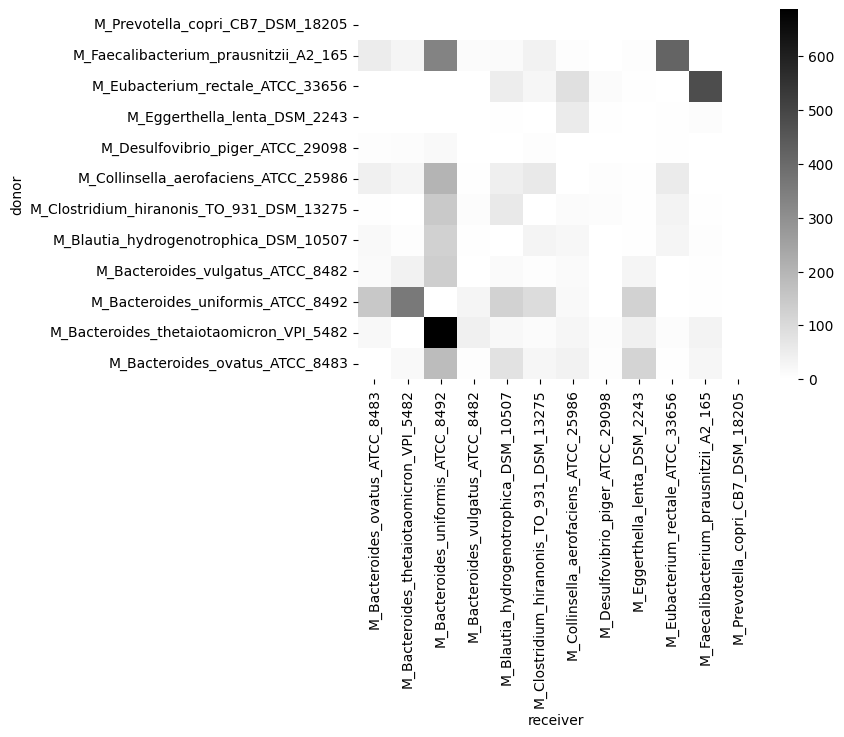

In [24]:
receivers_gut = cross_feeding_fixed_abundance_gut.copy()
receivers_gut = receivers_gut.dropna().groupby(["receiver","donor"]).sum()["rate?"]\
                    .unstack().fillna(0)

receivers_gut = receivers_gut.sort_index().T.sort_index(ascending=False).T
sns.heatmap(receivers_gut.T,
               cmap="binary",
               xticklabels=1,
               yticklabels=1,
               #method="ward"
              )

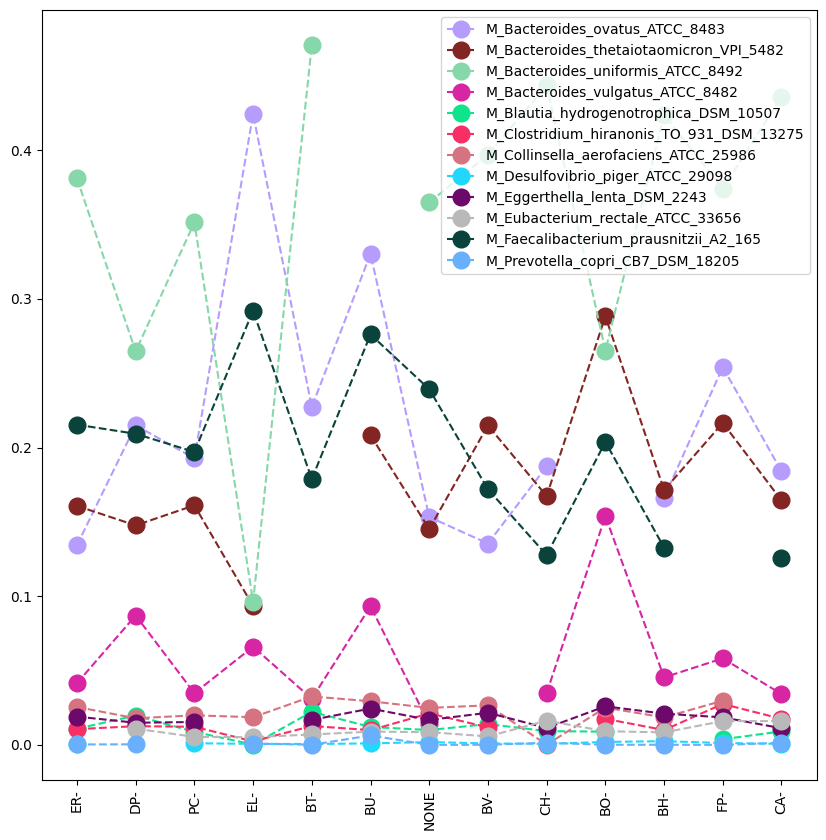

In [25]:
relative_abundance_gut_plot  = relative_abundance_fixed_abundance_gut.sort_index()
ax = relative_abundance_gut_plot.T.plot(rot=90,
                            marker="o",
                            markersize=12,
                            linestyle="--",
                            figsize=(10,10),
                             cmap=cmap)

ax.set_xticks(np.arange(len(relative_abundance_gut_plot.T.index)))
labels = ax.set_xticklabels(relative_abundance_gut_plot.T.index)

### Gut microbiome

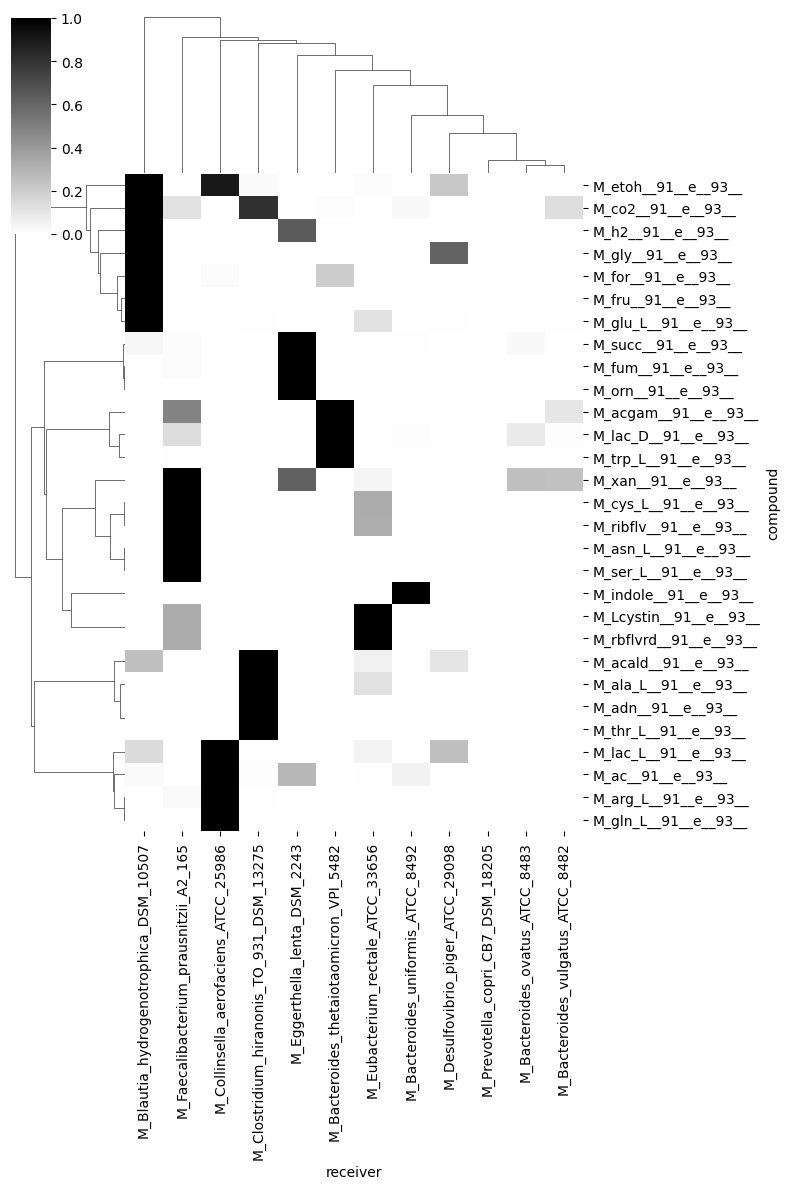

In [26]:
receivers_gut = cross_feeding_gut.copy()
receivers_gut = receivers_gut.dropna().groupby(["receiver","compound"]).sum()["rate?"]\
                    .unstack().fillna(0)


receivers_gut = receivers_gut.loc[:,receivers_gut.sum()>1]

sns.clustermap(receivers_gut.T,
               cmap="binary",
               xticklabels=1,
               yticklabels=1,
               method="ward",
               figsize=(8,12),
               standard_scale=0
              )

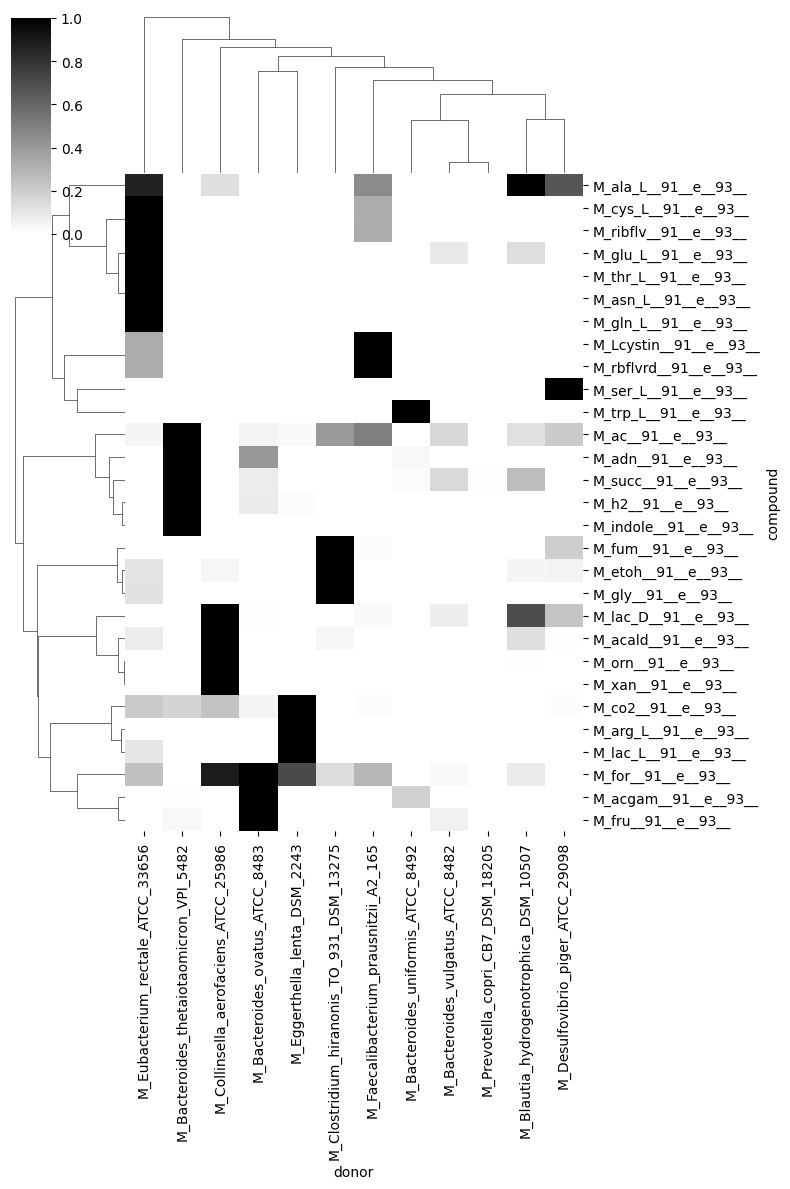

In [27]:
donors_gut = cross_feeding_gut.copy()
donors_gut = donors_gut.dropna().groupby(["donor","compound"]).sum()["rate?"]\
                    .unstack().fillna(0)


donors_gut = donors_gut.loc[:,donors_gut.sum()>1]

sns.clustermap(donors_gut.T,
               cmap="binary",
               xticklabels=1,
               yticklabels=1,
               method="ward",
               figsize=(8,12),
               standard_scale=0)

<Axes: xlabel='receiver', ylabel='donor'>

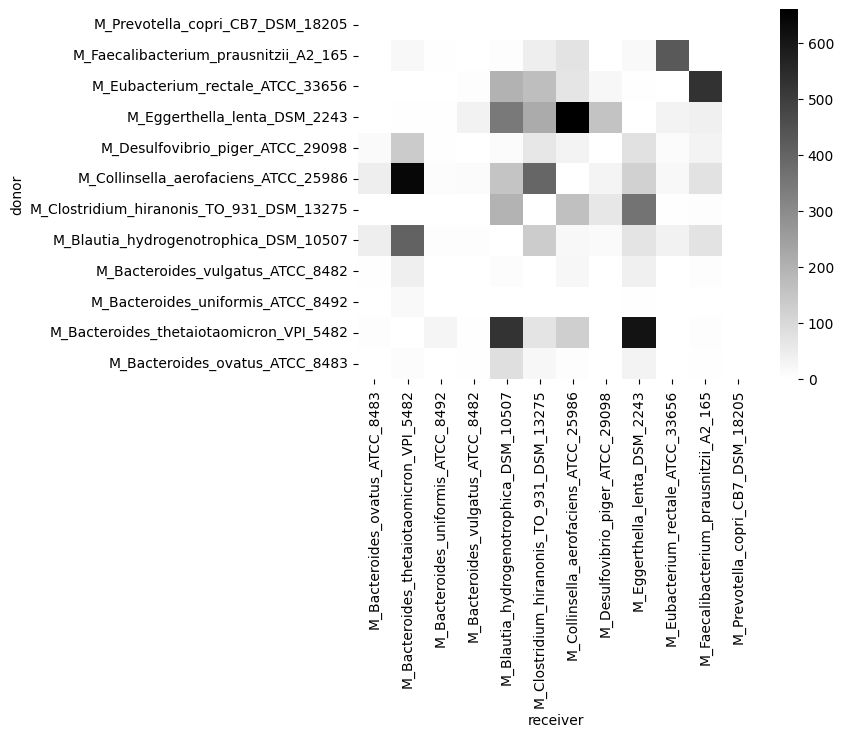

In [28]:
receivers_gut = cross_feeding_gut[cross_feeding_gut["rate?"]>1e-5]
receivers_gut = receivers_gut.dropna().groupby(["receiver","donor"]).sum()["rate?"]\
                    .unstack().fillna(0)

receivers_gut = receivers_gut.sort_index().T.sort_index(ascending=False).T
sns.heatmap(receivers_gut.T,
               cmap="binary",
               xticklabels=1,
               yticklabels=1,
               #method="ward"
              )

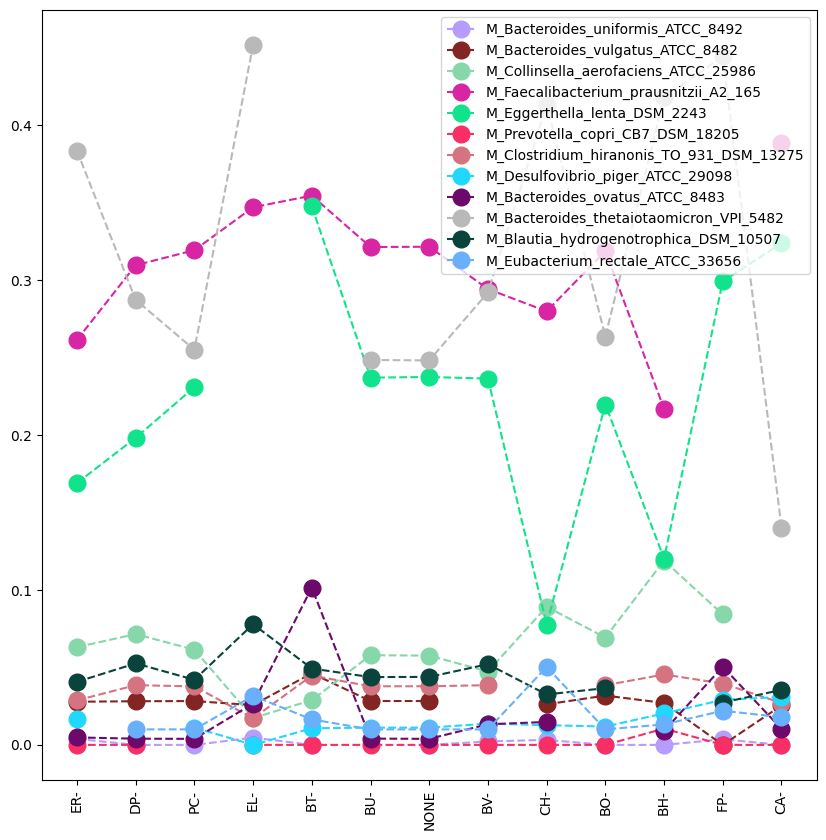

In [29]:
ax = relative_abundance_gut.T.plot(rot=90,
                            marker="o",
                            markersize=12,
                            linestyle="--",
                            figsize=(10,10),
                             cmap=cmap)

ax.set_xticks(np.arange(len(relative_abundance_gut.T.index)))
labels = ax.set_xticklabels(relative_abundance_gut.T.index)

#### Comparison in flux rates for when we have fixed abundance vs NOT fixed abundance

Each dot corresponds to the flux of a reaction.

<Axes: xlabel='Not fixed', ylabel='Fixed abundance'>

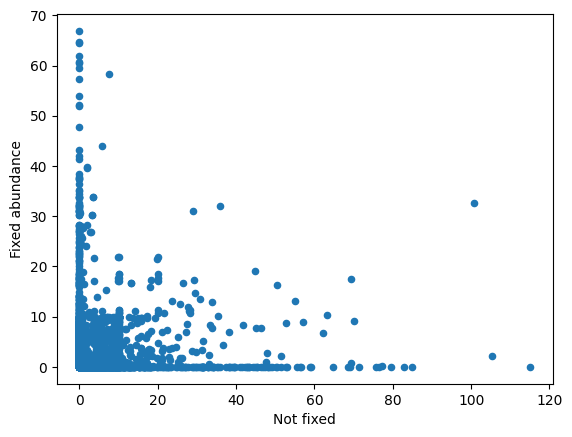

In [30]:
gut_cross_feeding = cross_feeding_gut.set_index(["community","donor","receiver","compound"])["rate?"]
gut_cross_feeding.name="Not fixed"

gut_cross_feeding_fixed = cross_feeding_fixed_abundance_gut.set_index(["community","donor","receiver","compound"])["rate?"]
gut_cross_feeding_fixed.name="Fixed abundance"

pd.concat([gut_cross_feeding,gut_cross_feeding_fixed],axis=1).fillna(0)\
        .plot.scatter(x="Not fixed",y="Fixed abundance")

#### Sum total donated flux vs relative abundance (for fixed rates)

Each dot corresponds to a community member.

<Axes: xlabel='Relative abundance', ylabel='Sum received flux (total)'>

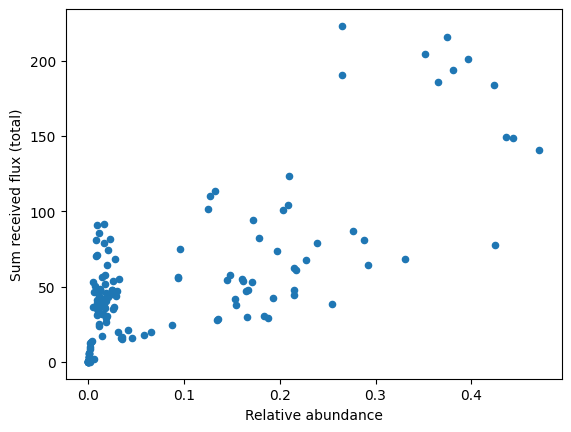

In [31]:
gut_CF = cross_feeding_fixed_abundance_gut.groupby(["community","receiver"]).sum()["rate?"]
gut_CF.name="Sum received flux (total)"
gut_RA = relative_abundance_fixed_abundance_gut.stack().reorder_levels(order=[1,0])
gut_RA.index.names = ["community","receiver"]
gut_RA.name ="Relative abundance"

pd.concat([gut_CF,gut_RA],axis=1).fillna(0)\
        .plot.scatter(x="Relative abundance",y="Sum received flux (total)")

#### Sum flux from media vs (fixed) relative abundance

Each dot corresponds to a community member.

<Axes: xlabel='Relative abundance', ylabel='Sum uptake flux (from environment)'>

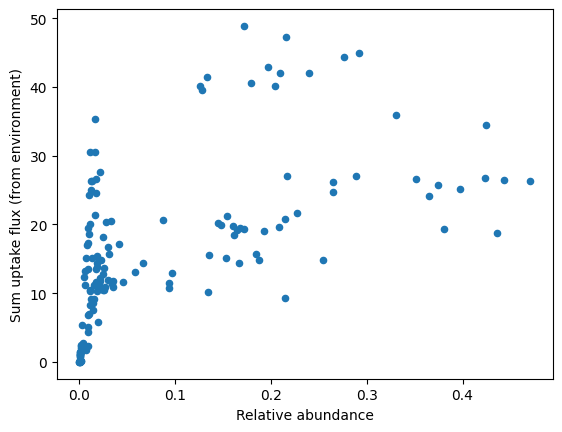

In [32]:
gut_CF = cross_feeding_fixed_abundance_gut[cross_feeding_fixed_abundance_gut.donor.isna()].groupby(["community","receiver"]).sum()["rate?"]
gut_CF.name="Sum uptake flux (from environment)"
gut_RA = relative_abundance_fixed_abundance_gut.stack().reorder_levels(order=[1,0])
gut_RA.index.names = ["community","receiver"]
gut_RA.name ="Relative abundance"

pd.concat([gut_CF,gut_RA],axis=1).fillna(0)\
        .plot.scatter(x="Relative abundance",y="Sum uptake flux (from environment)")

#### Sum flux in interactions vs (fixed) relative abundance 

<Axes: xlabel='Relative abundance', ylabel='Sum flux'>

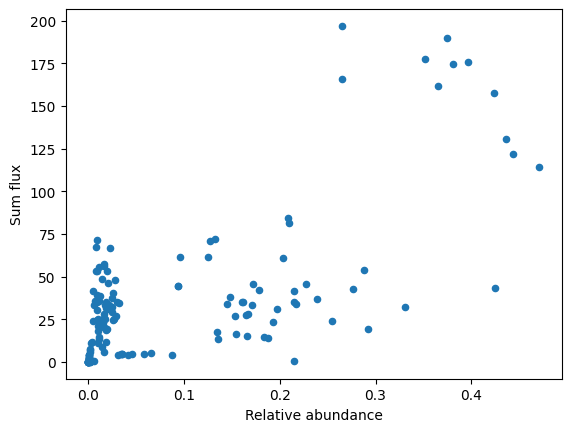

In [33]:
gut_CF = cross_feeding_fixed_abundance_gut.dropna().groupby(["community","receiver"]).sum()["rate?"]
gut_CF.name="Sum flux"
gut_RA = relative_abundance_fixed_abundance_gut.stack().reorder_levels(order=[1,0])
gut_RA.index.names = ["community","receiver"]
gut_RA.name ="Relative abundance"

pd.concat([gut_CF,gut_RA],axis=1).fillna(0)\
        .plot.scatter(x="Relative abundance",y="Sum flux")